# CS 725 · Hinglish sentiment · First baseline

This notebook gets the data and runs the first baseline (TF-IDF + Logistic Regression on raw text).

**Goal for today:** all four of us run this and get **the same macro-F1**. If we do, the data, splits and scoring are consistent and everything we build later is comparable.

* Works on Colab or Kaggle. No GPU is needed for this notebook.
* On Kaggle, turn **Internet on** (Settings → Internet) so the data can download.

## 1. Get the code
Finds the project folder if you already have it (local run). Clones only if it isn't there yet (Colab/Kaggle). Safe to re-run: it never creates a new folder twice.

In [22]:
import os
from pathlib import Path

LOCAL = Path("/Users/kartheek/Desktop/IITB Files/FML/cs725-hinglish-sentiment")   # your laptop
COLAB = Path("/content/Hinglish-sentiment-analysis")  # Google Colab

if LOCAL.exists():
    os.chdir(LOCAL)
else:
    if not COLAB.exists():
        !git clone -q https://github.com/Kartheek-pallem/Hinglish-sentiment-analysis.git /content/Hinglish-sentiment-analysis
    os.chdir(COLAB)

print("Working in:", Path.cwd())

Working in: /Users/kartheek/Desktop/IITB Files/FML/cs725-hinglish-sentiment


In [23]:
%pip install -q -r requirements.txt

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 2. Download SentiMix and build the CSVs
Expect 14,000 / 3,000 / 3,000 tweets and **ALL CHECKS PASSED** at the end. If any check needs a look, post the output in the group chat.

In [24]:
!python3 -m src.data

Parsing and checking ...
  [train_14k_split_conll.txt] empty token skipped: 32
  [dev_3k_split_conll.txt] empty token skipped: 2
  [Hindi_test_unalbelled_conll_updated.txt] empty token skipped: 4
  test: 0 tweets without a label, 0 labels without a tweet
  train:  14000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.331, 'negative': 0.293}
  val  :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.327, 'negative': 0.297}
  test :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.367, 'positive': 0.333, 'negative': 0.3}
  word tags: 522563 tokens; share by tag: {'Hin': 0.465, 'Eng': 0.332, 'O': 0.202, 'EMT': 0.001}
  ALL CHECKS PASSED


## 3. Check the code works

In [25]:
!python3 -m unittest discover -s tests

  [train_14k_split_conll.txt] empty token skipped: 1
  [train_14k_split_conll.txt] missing or unknown tag set to O: 1
  [dev_3k_split_conll.txt] empty token skipped: 1
  [dev_3k_split_conll.txt] missing or unknown tag set to O: 1
  test: 0 tweets without a label, 0 labels without a tweet
  train:      3 tweets (EXPECTED 14000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  val  :      3 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  test :      2 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.5, 'negative': 0.5}
  word tags: 34 tokens; share by tag: {'Hin': 0.471, 'Eng': 0.353, 'O': 0.118, 'EMT': 0.059}
  SOME CHECKS NEED A LOOK (see above)
.../Users/kartheek/Library/Python/3.9/lib/python/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecation

## 4. Run the baseline
Set `OWNER` to your own person number (person1 … person4).

In [26]:
OWNER = "person1"   # <- Mahesh
!python3 scripts/baseline_lr.py --owner $OWNER

train 14000 tweets, 42618 features (word)
person1_logreg_sentimix-val_raw_word: macro-F1 0.6167 | accuracy 0.6127 | F1 neg/neu/pos 0.644/0.534/0.672
person1_logreg_sentimix-test_raw_word: macro-F1 0.6762 | accuracy 0.6720 | F1 neg/neu/pos 0.695/0.594/0.740


In [27]:
!python3 scripts/svm.py --owner person2 # first run: default C = 1  <-Manikanta

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-test_raw_word: macro-F1 0.6396 | accuracy 0.6357 | F1 neg/neu/pos 0.666/0.548/0.704


In [28]:
!python3 scripts/svm.py --owner person2 --tune # pick C on validation, then test once

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.5811 | accuracy 0.5777 | F1 neg/neu/pos 0.565/0.528/0.650
person2_svm_sentimix-val_raw_word: macro-F1 0.6033 | accuracy 0.5997 | F1 neg/neu/pos 0.621/0.517/0.672
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-val_raw_word: macro-F1 0.6110 | accuracy 0.6073 | F1 neg/neu/pos 0.647/0.520/0.666
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-val_raw_word: macro-F1 0.5838 | accuracy 0.5797 | F1 neg/neu/pos 0.623/0.502/0.626
best C on validation: 0.1 (macro-F1 0.6121)
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-test_raw_word: macro-F1 0.6765 | accuracy 0.6730 | F1 neg/neu/pos 0.701/0.587/0.742


In [29]:
!python3 scripts/svm.py --owner person2 --tune --features char # character n-grams

train 14000 tweets, 122301 features (char, raw)
person2_svm_sentimix-val_raw_char: macro-F1 0.6040 | accuracy 0.6007 | F1 neg/neu/pos 0.594/0.559/0.659
person2_svm_sentimix-val_raw_char: macro-F1 0.6199 | accuracy 0.6160 | F1 neg/neu/pos 0.635/0.555/0.669
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-val_raw_char: macro-F1 0.6120 | accuracy 0.6087 | F1 neg/neu/pos 0.628/0.538/0.670
person2_svm_sentimix-val_raw_char: macro-F1 0.5982 | accuracy 0.5947 | F1 neg/neu/pos 0.628/0.519/0.648
person2_svm_sentimix-val_raw_char: macro-F1 0.5806 | accuracy 0.5767 | F1 neg/neu/pos 0.620/0.498/0.624
best C on validation: 0.1 (macro-F1 0.6207)
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-test_raw_char: macro-F1 0.6826 | accuracy 0.6780 | F1 neg/neu/pos 0.710/0.605/0.733


In [36]:
!python3 scripts/naive_bayes.py --owner person3                        # first run: default alpha = 1


train 14000 tweets, 42618 features (word, raw)
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.6118 | accuracy 0.6070 | F1 neg/neu/pos 0.626/0.536/0.673
person3_naive-bayes_sentimix-test_raw_word: macro-F1 0.6693 | accuracy 0.6643 | F1 neg/neu/pos 0.686/0.587/0.735


In [ ]:
!python3 scripts/naive_bayes.py --owner person3 --tune                 # pick alpha on validation

zsh:1: command not found: python


In [37]:
!python3 scripts/naive_bayes.py --owner person3 --tune --features char

train 14000 tweets, 122301 features (char, raw)
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5824 | accuracy 0.5793 | F1 neg/neu/pos 0.618/0.492/0.637
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5879 | accuracy 0.5860 | F1 neg/neu/pos 0.631/0.487/0.646
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5860 | accuracy 0.5843 | F1 neg/neu/pos 0.627/0.478/0.652
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5984 | accuracy 0.5947 | F1 neg/neu/pos 0.625/0.513/0.658
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5934 | accuracy 0.5917 | F1 neg/neu/pos 0.565/0.568/0.648
best alpha on validation: 0.3 (macro-F1 0.5984)
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5984 | accuracy 0.5947 | F1 neg/neu/pos 0.625/0.513/0.658
person3_naive-bayes_sentimix-test_raw_char: macro-F1 0.6457 | accuracy 0.6413 | F1 neg/neu/pos 0.681/0.551/0.705


In [38]:
!python3 scripts/naive_bayes.py --owner person3 --tune --variant complement   # optional Complement NB

train 14000 tweets, 42618 features (word, raw)
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5677 | accuracy 0.5743 | F1 neg/neu/pos 0.629/0.412/0.662
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5710 | accuracy 0.5790 | F1 neg/neu/pos 0.632/0.411/0.670
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5767 | accuracy 0.5860 | F1 neg/neu/pos 0.643/0.414/0.674
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5864 | accuracy 0.5963 | F1 neg/neu/pos 0.649/0.427/0.683
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5874 | accuracy 0.5980 | F1 neg/neu/pos 0.654/0.426/0.682
best alpha on validation: 1.0 (macro-F1 0.5874)
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5874 | accuracy 0.5980 | F1 neg/neu/pos 0.654/0.426/0.682
person3_complement-nb_sentimix-test_raw_word: macro-F1 0.6398 | accuracy 0.6510 | F1 neg/neu/pos 0.708/0.468/0.743


In [30]:
!python3 scripts/decision_tree.py --owner person4                     # default: no size limit


train 14000 tweets, 20000 features (word, raw)
tree size: 6985 nodes, 283 levels deep
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4924 | accuracy 0.4900 | F1 neg/neu/pos 0.492/0.455/0.530
person4_decision-tree_sentimix-test_raw_word_s42: macro-F1 0.5088 | accuracy 0.5057 | F1 neg/neu/pos 0.508/0.453/0.566


In [31]:
!python3 scripts/decision_tree.py --owner person4 --tune              # pick settings on validation d100,l5

train 14000 tweets, 20000 features (word, raw)
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4942 | accuracy 0.4947 | F1 neg/neu/pos 0.489/0.497/0.497
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4868 | accuracy 0.4873 | F1 neg/neu/pos 0.483/0.490/0.487
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.5037 | accuracy 0.5020 | F1 neg/neu/pos 0.499/0.489/0.523
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4863 | accuracy 0.4850 | F1 neg/neu/pos 0.492/0.475/0.491
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.5026 | accuracy 0.5007 | F1 neg/neu/pos 0.498/0.479/0.530
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4876 | accuracy 0.4860 | F1 neg/neu/pos 0.483/0.470/0.510
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4924 | accuracy 0.4900 | F1 neg/neu/pos 0.492/0.455/0.530
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4889 | accuracy 0.4870 | F1 neg/neu/pos 0.486/0.466/0.515
best on v

In [32]:
!python3 scripts/decision_tree.py --owner person4 --tune --features char # d20,l1

train 14000 tweets, 20000 features (char, raw)
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5108 | accuracy 0.5120 | F1 neg/neu/pos 0.492/0.516/0.524
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5069 | accuracy 0.5087 | F1 neg/neu/pos 0.489/0.517/0.514
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5001 | accuracy 0.4977 | F1 neg/neu/pos 0.501/0.467/0.533
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4995 | accuracy 0.4977 | F1 neg/neu/pos 0.500/0.477/0.521
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4834 | accuracy 0.4810 | F1 neg/neu/pos 0.486/0.442/0.523
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5014 | accuracy 0.4993 | F1 neg/neu/pos 0.505/0.469/0.530
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4834 | accuracy 0.4810 | F1 neg/neu/pos 0.486/0.442/0.523
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5014 | accuracy 0.4993 | F1 neg/neu/pos 0.505/0.469/0.530
best on v

## 5. Look at the result
Post your **sentimix_test macro-F1** in the group chat. Everyone's number should match exactly.

,run_id,dataset,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
100,person4_decision-tree_sentimix-val_raw_char_s42,sentimix_val,0.4834,0.4810,0.4859,0.4418,0.5226
101,person4_decision-tree_sentimix-val_raw_char_s42,sentimix_val,0.5014,0.4993,0.5053,0.4689,0.5299
102,person4_decision-tree_sentimix-val_raw_char_s42,sentimix_val,0.5108,0.5120,0.4923,0.5165,0.5236
103,person4_decision-tree_sentimix-test_raw_char_s42,sentimix_test,0.5385,0.5363,0.5337,0.5213,0.5606


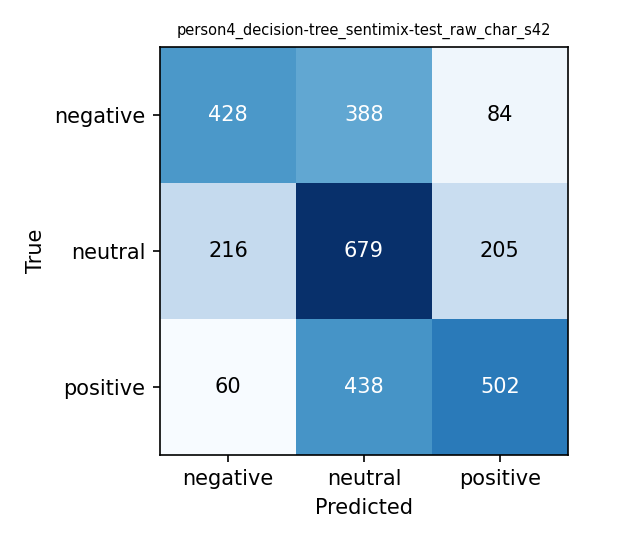

In [40]:
import sys; sys.path.insert(0, ".")
from src.evaluate import load_results
from IPython.display import Image, display
res = load_results()
display(res[["run_id", "dataset", "macro_f1", "accuracy", "f1_negative", "f1_neutral", "f1_positive"]].tail(4))
display(Image(f"results/confusion/{res.run_id.iloc[-1]}.png", width=380))

## 6. Optional: two more quick runs

* Character n-grams instead of words: `!python scripts/baseline_lr.py --owner $OWNER --features char`
* Tune C on validation, then test once: `!python scripts/baseline_lr.py --owner $OWNER --tune`

These are the first two of the six classical runs in the plan. To keep results, commit your `results/results_<you>.csv` and `results/preds/` files to the repo.